In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,GridSearchCV,cross_val_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import r2_score
from sklearn.datasets import load_iris

In [17]:
df=pd.DataFrame(load_iris(return_X_y=False).data,columns=load_iris(return_X_y=False).feature_names)
df['target']=load_iris(return_X_y=False).target

In [18]:
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


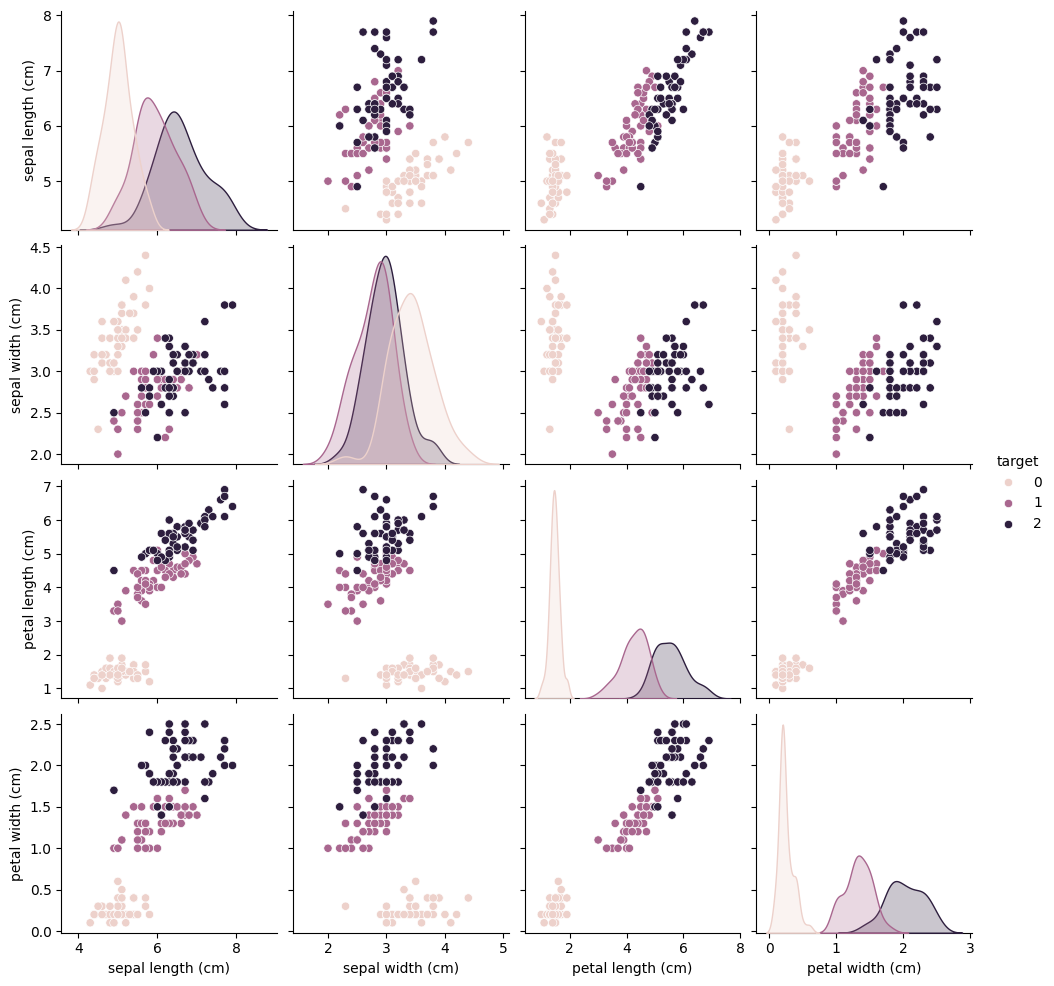

In [25]:
import seaborn as sns
sns.pairplot(df,hue='target')

In [38]:
X=df.iloc[:,:2]
X
y=df.iloc[:,-1]
y

,target
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


In [29]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [39]:
clf1=LogisticRegression()
clf2=RandomForestClassifier()
clf3=KNeighborsClassifier()

In [40]:
estimators=[('lor',clf1),('rfc',clf2),('knn',clf3)]

In [43]:
for estimator in estimators:
    x=cross_val_score(estimator[1],X,y,cv=10,scoring='accuracy').mean()
    print(estimator[0],np.round(x,2))

lor 0.81
rfc 0.73
knn 0.76


In [58]:
from sklearn.ensemble import VotingClassifier,VotingRegressor

In [54]:
vc=VotingClassifier(estimators=estimators,voting='hard')

In [55]:
x=cross_val_score(vc,X,y,cv=10,scoring='accuracy').mean()
print(np.round(x,2))

0.76


In [57]:
maxi=0
for i in range(1,5):
  for j in range(1,3):
    for k in range(1,3):
      vc=VotingClassifier(estimators=estimators,voting='hard',weights=[i,j,k])
      x=cross_val_score(vc,X,y,cv=10,scoring='accuracy').mean()
      maxi=max(maxi,np.round(x,2))
print(maxi)

0.81


In [65]:
from sklearn.svm import SVR
clf1=LinearRegression()
clf2=DecisionTreeRegressor()
clf3=SVR()
estimators1=[('lr',clf1),('dt',clf2),('svr',clf3)]
vr=VotingRegressor(estimators=estimators1)

In [90]:
from sklearn.datasets import fetch_california_housing
X1,y1 = fetch_california_housing(return_X_y=True)

In [91]:
X1

array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
          37.88      , -122.23      ],
       [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
          37.86      , -122.22      ],
       [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
          37.85      , -122.24      ],
       ...,
       [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
          39.43      , -121.22      ],
       [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
          39.43      , -121.32      ],
       [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
          39.37      , -121.24      ]])

In [92]:
df=pd.DataFrame(X1,columns=fetch_california_housing(return_X_y=False).feature_names)
X1=df.iloc[:,:-1]
for names in X1.columns:
  X1_max=max(X1[names])
  X1_min=min(X1[names])
  X1[names]=(X1[names]-X1_min)/(X1_max-X1_min)


/tmp/ipykernel_540/2281272485.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X1[names]=(X1[names]-X1_min)/(X1_max-X1_min)


In [89]:
y1

array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894])

In [93]:
X1

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude
0,0.539668,0.784314,0.043512,0.020469,0.008941,0.001499,0.567481
1,0.538027,0.392157,0.038224,0.018929,0.067210,0.001141,0.565356
2,0.466028,1.000000,0.052756,0.021940,0.013818,0.001698,0.564293
3,0.354699,1.000000,0.035241,0.021929,0.015555,0.001493,0.564293
4,0.230776,1.000000,0.038534,0.022166,0.015752,0.001198,0.564293
...,...,...,...,...,...,...,...
20635,0.073130,0.470588,0.029769,0.023715,0.023599,0.001503,0.737513
20636,0.141853,0.333333,0.037344,0.029124,0.009894,0.001956,0.738576
20637,0.082764,0.313725,0.030904,0.023323,0.028140,0.001314,0.732200
20638,0.094295,0.333333,0.031783,0.024859,0.020684,0.001152,0.732200


In [94]:
for estimator in estimators1:
    x=cross_val_score(estimator[1],X1,y1,cv=10,scoring='r2').mean()
    print(estimator[0],np.round(x,2))

lr 0.42
dt 0.08
svr 0.45


In [95]:
x=cross_val_score(vr,X1,y1,cv=10,scoring='r2').mean()
print(np.round(x,2))

0.48


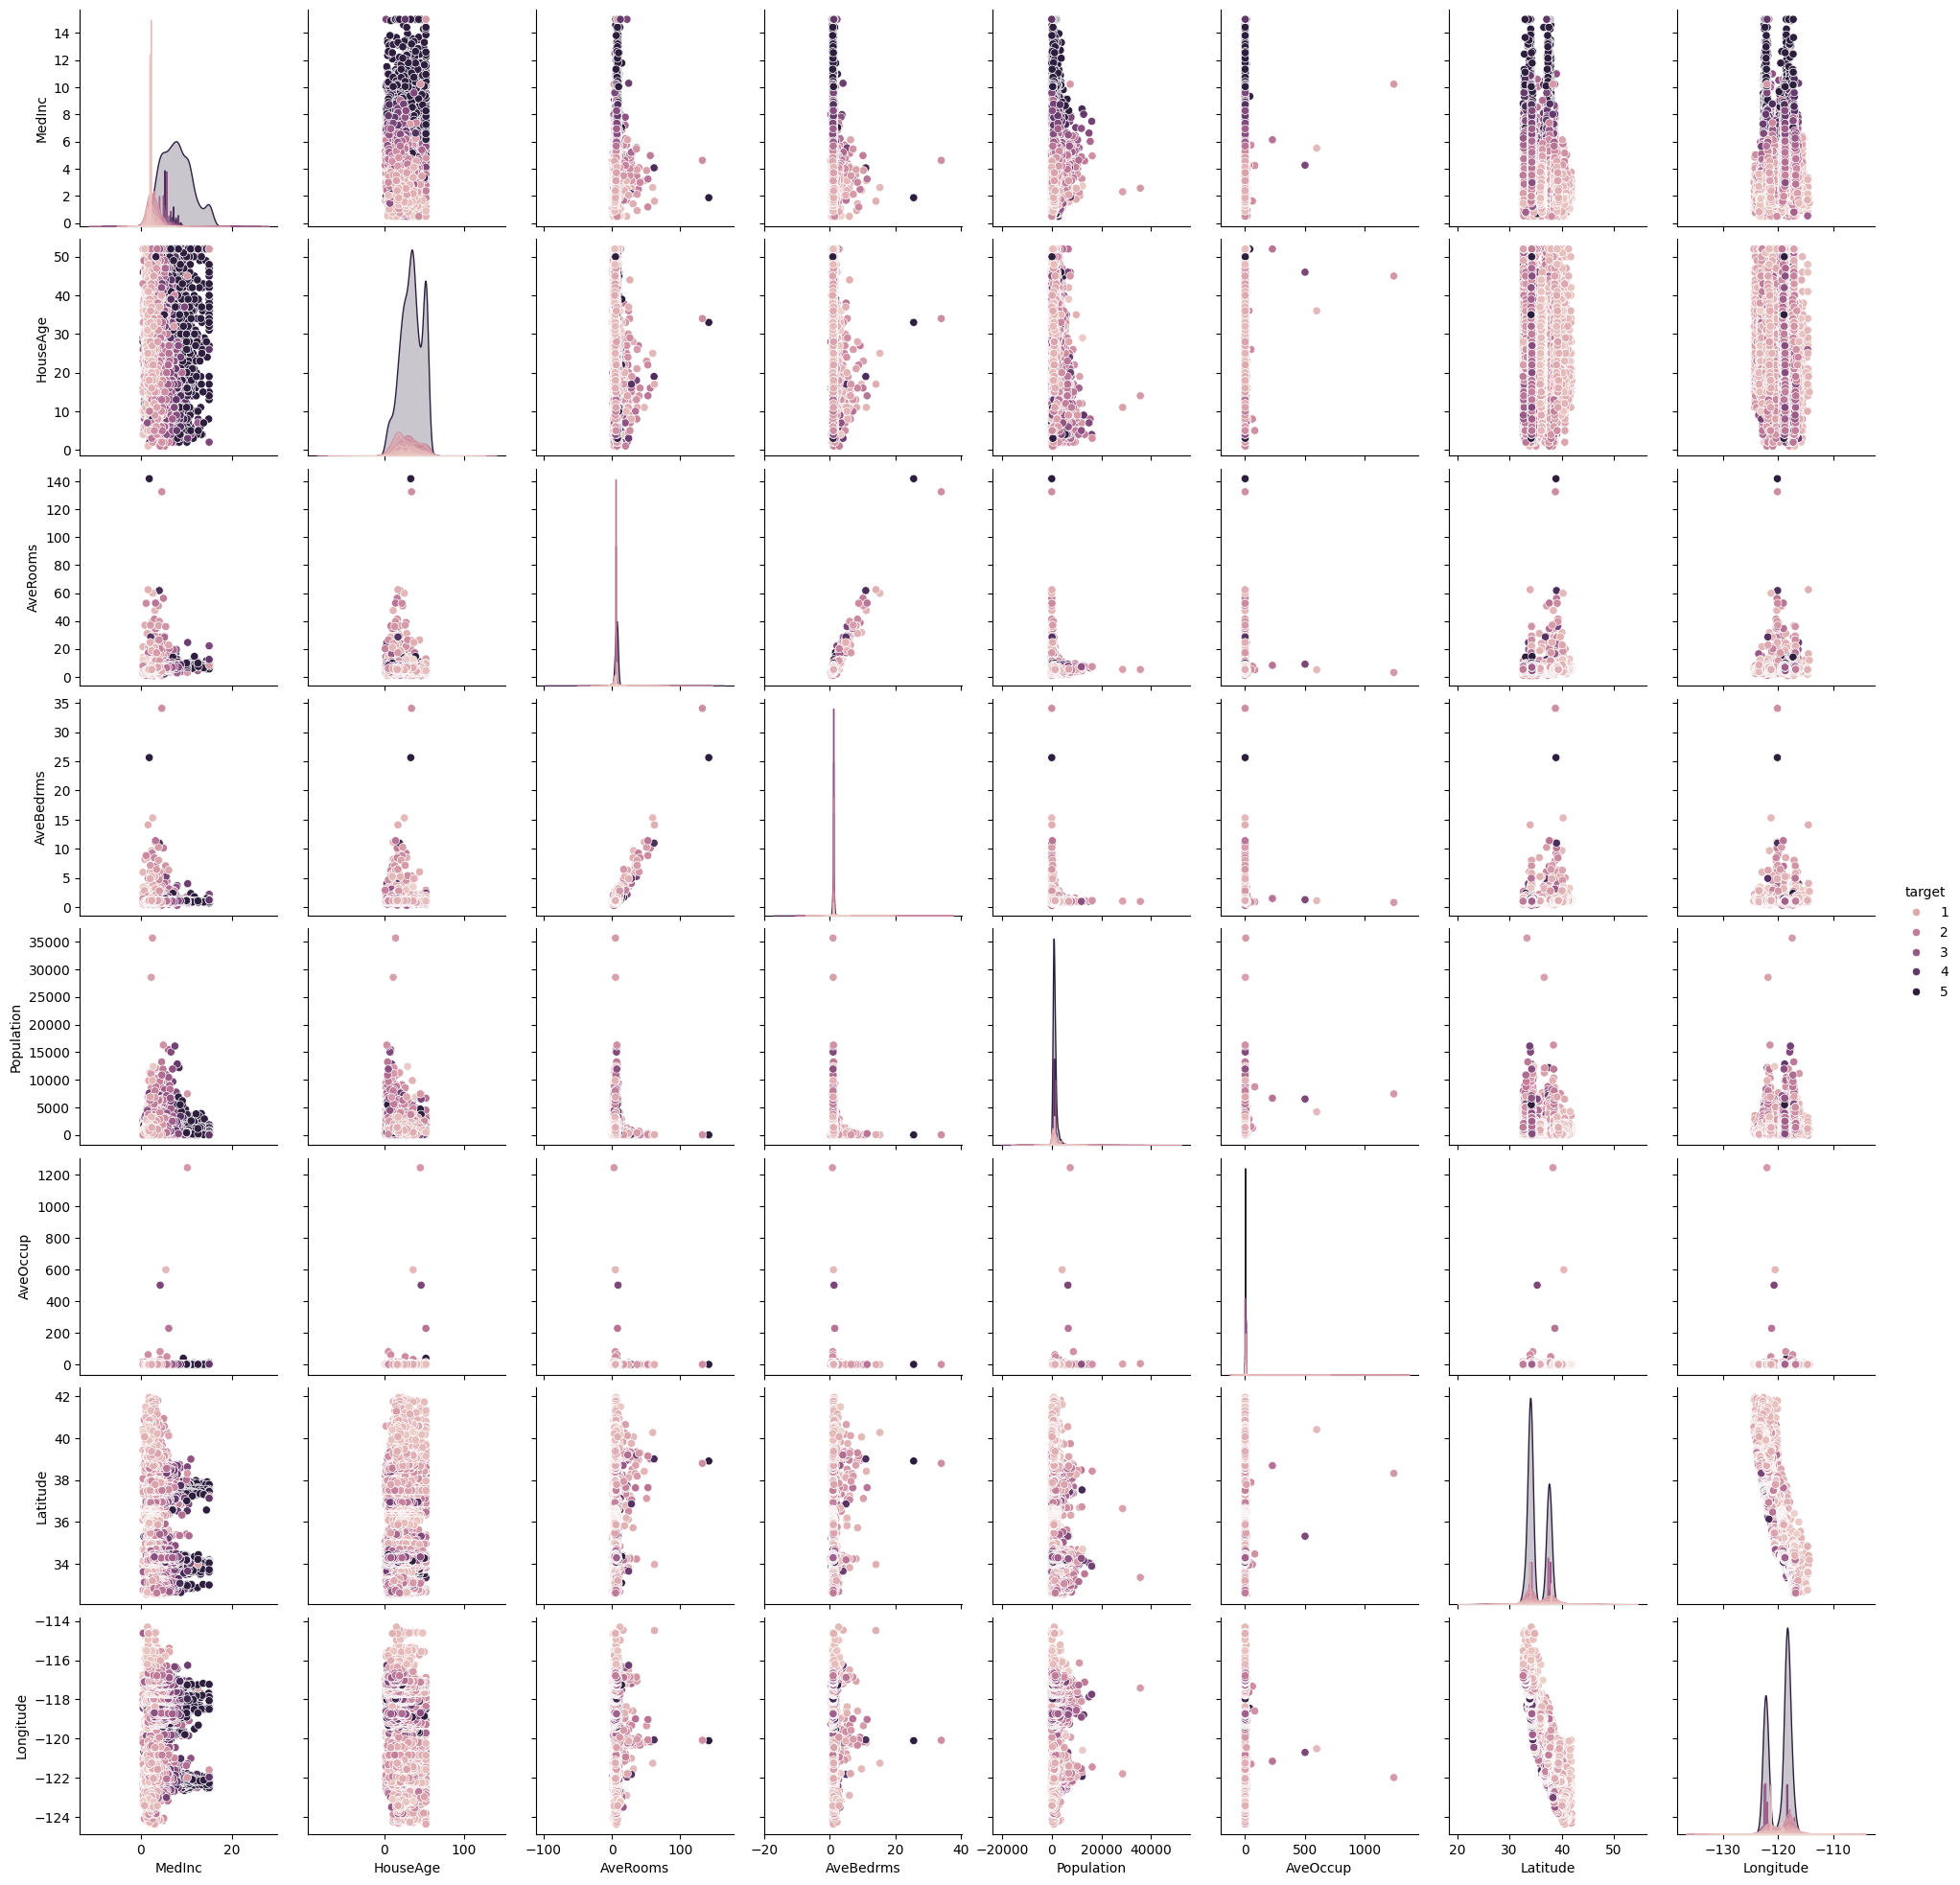

In [96]:
df['target']=y1
sns.pairplot(df,hue='target')